### Step 1: Import Libraries



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc

np.random.seed(42)

### Step 2: Set the Number of Samples

Generate 10,000 samples for each of the three classes. Use an 80/20 training and testing split.

In [2]:
N = 10000
TEST_SIZE = 0.20
classes = [0, 1, 2]

means = {
    0: np.array([0.0, 0.0]),
    1: np.array([5.0, 5.0]),
    2: np.array([2.0, -3.0])
}

### Step 3: Define Covariance Matrices



In [6]:
experiments = {
    "Isotropic - Identical": [
        [[2, 0], [0, 2]],
        [[2, 0], [0, 2]],
        [[2, 0], [0, 2]]
    ],

    "Isotropic - Different": [
        [[1, 0], [0, 1]],
        [[2, 0], [0, 2]],
        [[3, 0], [0, 3]]
    ],

    "Diagonal - Identical": [
        [[2, 0], [0, 1]],
        [[2, 0], [0, 1]],
        [[2, 0], [0, 1]]
    ],

    "Diagonal - Different": [
        [[1, 0], [0, 1]],
        [[4, 0], [0, 1]],
        [[2, 0], [0, 3]]
    ],

    "Full - Identical": [
        [[2, 1], [1, 2]],
        [[2, 1], [1, 2]],
        [[2, 1], [1, 2]]
    ],

    "Full - Different": [
        [[2, 1], [1, 2]],
        [[2, -1], [-1, 2]],
        [[3, 0.7], [0.7, 1.5]]
    ]
}

### Step 4: Gaussian Generation, MLE, and Classification Functions



In [7]:
# Generate standard Gaussian samples using Box-Muller polar method
def box_muller_polar(n, rng):
    values = []

    while len(values) < n:
        u1, u2 = rng.uniform(-1, 1, 2)
        s = u1**2 + u2**2

        if 0 < s < 1:
            k = np.sqrt(-2 * np.log(s) / s)

            values.append([u1 * k, u2 * k])

            if len(values) < n:
                values.append([u2 * k, -u1 * k])

    return np.asarray(values[:n])


# Generate three Gaussian classes using covariance transformation
def generate_dataset(covariance_list, seed=42):
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []

    for c in classes:
        Z = box_muller_polar(N, rng)
        covariance = np.asarray(covariance_list[c], dtype=float)

        eigenvalues, eigenvectors = np.linalg.eigh(covariance)

        if np.any(eigenvalues <= 0):
            raise ValueError("Covariance matrix must be positive definite.")

        covariance_sqrt = (
            eigenvectors
            @ np.diag(np.sqrt(eigenvalues))
            @ eigenvectors.T
        )

        X_class = Z @ covariance_sqrt.T + means[c]

        X_list.append(X_class)
        y_list.append(np.full(N, c))

    return np.vstack(X_list), np.concatenate(y_list)


# Estimate class means, covariance matrices, and prior probabilities using MLE
def estimate_mle(X_train, y_train, class_labels):
    estimated_means = {}
    estimated_covariances = {}
    priors = {}

    for c in class_labels:
        X_class = X_train[y_train == c]

        mean = np.mean(X_class, axis=0)
        centered = X_class - mean
        covariance = (centered.T @ centered) / len(X_class)

        estimated_means[c] = mean
        estimated_covariances[c] = covariance
        priors[c] = len(X_class) / len(X_train)

    return estimated_means, estimated_covariances, priors


# Calculate Gaussian discriminant scores
def gaussian_scores(X, estimated_means, estimated_covariances, priors, class_labels):
    score_list = []

    for c in class_labels:
        mean = estimated_means[c]
        covariance = estimated_covariances[c] + 1e-6 * np.eye(2)

        inverse_covariance = np.linalg.inv(covariance)
        determinant = np.linalg.det(covariance)
        difference = X - mean

        score = (
            -0.5 * np.sum(
                (difference @ inverse_covariance) * difference,
                axis=1
            )
            - 0.5 * np.log(determinant)
            + np.log(priors[c])
        )

        score_list.append(score)

    return np.column_stack(score_list)


# Plot decision boundaries with equal X1 and X2 scales
def plot_decision_boundary(
    X_test, y_test, estimated_means,
    estimated_covariances, priors, class_labels, title
):
    # Use identical limits for both axes
    axis_min = min(X_test[:, 0].min(), X_test[:, 1].min()) - 1
    axis_max = max(X_test[:, 0].max(), X_test[:, 1].max()) + 1

    xx, yy = np.meshgrid(
        np.linspace(axis_min, axis_max, 300),
        np.linspace(axis_min, axis_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    grid_scores = gaussian_scores(
        grid, estimated_means, estimated_covariances,
        priors, class_labels
    )

    regions = np.argmax(grid_scores, axis=1).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(9, 9))

    region_colors = ["#EAF2F8", "#FFF4E5", "#FCEEF3"]
    point_colors = ["#2980B9", "#FF8C33", "#32A852"]
    mean_colors = ["red", "purple", "saddlebrown"]

    ax.contourf(
        xx, yy, regions,
        levels=np.arange(len(class_labels) + 1) - 0.5,
        colors=region_colors[:len(class_labels)],
        alpha=0.8
    )

    ax.contour(
        xx, yy, regions,
        levels=np.arange(len(class_labels) - 1) + 0.5,
        colors="black",
        linewidths=1.1
    )

    for i, c in enumerate(class_labels):
        mask = y_test == c

        ax.scatter(
            X_test[mask, 0], X_test[mask, 1],
            s=12,
            color=point_colors[i % len(point_colors)],
            alpha=0.5,
            edgecolors="none",
            label=f"Class {i + 1}"
        )

    for i, c in enumerate(class_labels):
        mean = estimated_means[c]

        ax.scatter(
            mean[0], mean[1],
            marker="X",
            s=180,
            color=mean_colors[i % len(mean_colors)],
            edgecolors="black",
            linewidths=1.2,
            label=f"Mean {i + 1}",
            zorder=5
        )

    ax.set_xlim(axis_min, axis_max)
    ax.set_ylim(axis_min, axis_max)
    ax.set_aspect("equal", adjustable="box")

    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_title(title)
    ax.grid(alpha=0.2)
    ax.legend(loc="upper right", fontsize=9)

    fig.tight_layout()
    plt.show()


# Plot a blue confusion matrix
def plot_confusion_matrix(y_test, y_pred, class_labels, title):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)

    print("\nConfusion Matrix:")
    print(cm)

    fig, ax = plt.subplots(figsize=(6, 5))

    image = ax.imshow(cm, cmap="Blues", interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    labels = [f"Class {i + 1}" for i in range(len(class_labels))]
    ax.set_xticks(range(len(class_labels)))
    ax.set_yticks(range(len(class_labels)))
    ax.set_xticklabels(labels)
    ax.set_yticklabels(labels)

    threshold = cm.max() / 2 if cm.size else 0

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(
                j, i, f"{cm[i, j]:,}",
                ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black"
            )

    ax.set_xticks(np.arange(-0.5, len(class_labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(class_labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="minor", bottom=False, left=False)

    fig.colorbar(image, ax=ax)
    fig.tight_layout()
    plt.show()

    return cm


# Plot one-vs-rest ROC curves
def plot_roc(y_test, scores, class_labels, title):
    y_binary = label_binarize(y_test, classes=class_labels)

    fig, ax = plt.subplots(figsize=(8, 6))
    auc_values = {}

    colors = ["#1976D2", "#F57C00", "#2E7D32"]

    for i, c in enumerate(class_labels):
        fpr, tpr, _ = roc_curve(y_binary[:, i], scores[:, i])
        roc_auc = auc(fpr, tpr)
        auc_values[c] = roc_auc

        ax.plot(
            fpr, tpr,
            color=colors[i % len(colors)],
            linewidth=2,
            label=f"Class {i + 1} (AUC = {roc_auc:.3f})"
        )

    ax.plot([0, 1], [0, 1], "k--", label="Random Classifier")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.set_title(title)
    ax.legend(loc="lower right")
    ax.grid(alpha=0.2)

    fig.tight_layout()
    plt.show()

    print("\nROC-AUC Values:")
    for i, c in enumerate(class_labels):
        print(f"Class {i + 1}: {auc_values[c]:.4f}")

    return auc_values


# Run one complete experiment and display all outputs
def run_experiment(title, covariance_list, seed=42):
    print("\n" + "=" * 55)
    print(title)
    print("=" * 55)

    X, y = generate_dataset(covariance_list, seed)

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=TEST_SIZE,
        random_state=42,
        stratify=y
    )

    print("Total samples:", len(X))
    print("Training samples:", len(X_train))
    print("Testing samples:", len(X_test))

    estimated_means, estimated_covariances, priors = estimate_mle(
        X_train, y_train, classes
    )

    for c in classes:
        print(f"\nClass {c + 1}")
        print("Estimated Mean:", np.round(estimated_means[c], 4))
        print("Estimated Covariance:")
        print(np.round(estimated_covariances[c], 4))

    scores = gaussian_scores(
        X_test, estimated_means, estimated_covariances, priors, classes
    )

    y_pred = np.argmax(scores, axis=1)
    accuracy = accuracy_score(y_test, y_pred)

    print(f"\nTest Accuracy: {accuracy * 100:.2f}%")

    plot_decision_boundary(
        X_test, y_test, estimated_means, estimated_covariances,
        priors, classes, "Decision Boundary - " + title
    )

    cm = plot_confusion_matrix(
        y_test, y_pred, classes, "Confusion Matrix - " + title
    )

    auc_values = plot_roc(
        y_test, scores, classes, "ROC Curve - " + title
    )

    return {
        "accuracy": accuracy,
        "confusion_matrix": cm,
        "auc": auc_values
    }

### Experiment 1: Isotropic – Identical Covariance



Isotropic - Identical Covariance
Total samples: 30000
Training samples: 24000
Testing samples: 6000

Class 1
Estimated Mean: [-0.0098  0.0005]
Estimated Covariance:
[[ 2.0432 -0.0041]
 [-0.0041  2.0171]]

Class 2
Estimated Mean: [5.0298 4.9953]
Estimated Covariance:
[[ 1.9715 -0.0054]
 [-0.0054  1.9848]]

Class 3
Estimated Mean: [ 2.0101 -2.9945]
Estimated Covariance:
[[ 2.0445 -0.0037]
 [-0.0037  2.06  ]]

Test Accuracy: 92.43%


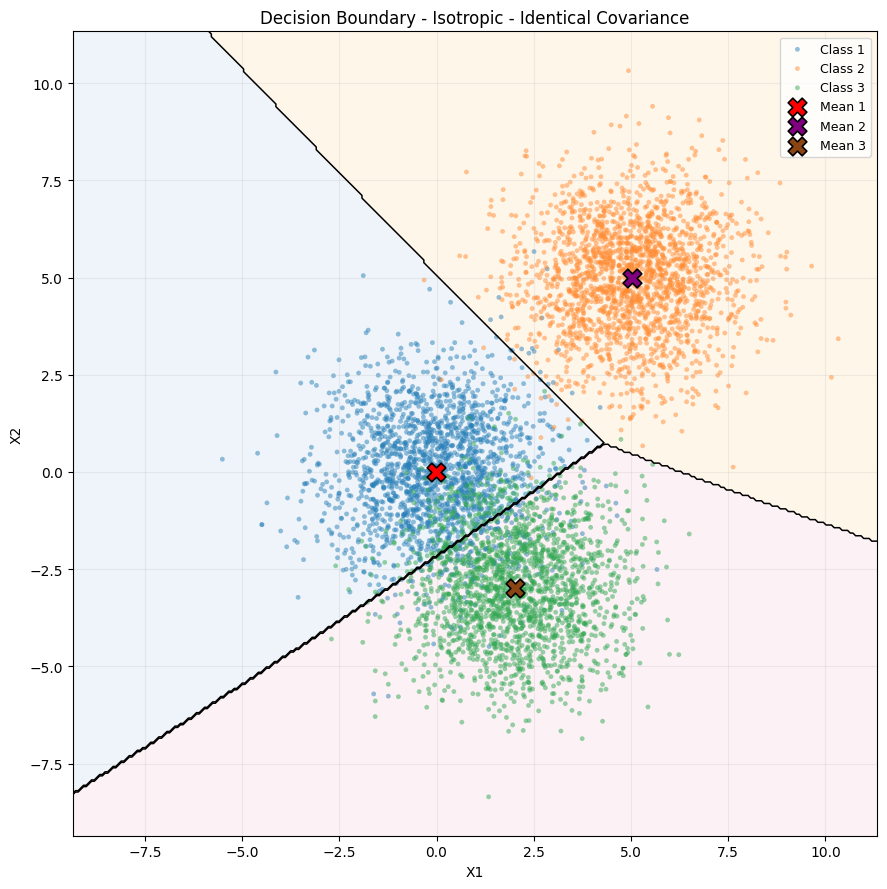


Confusion Matrix:
[[1771   19  210]
 [  14 1986    0]
 [ 210    1 1789]]


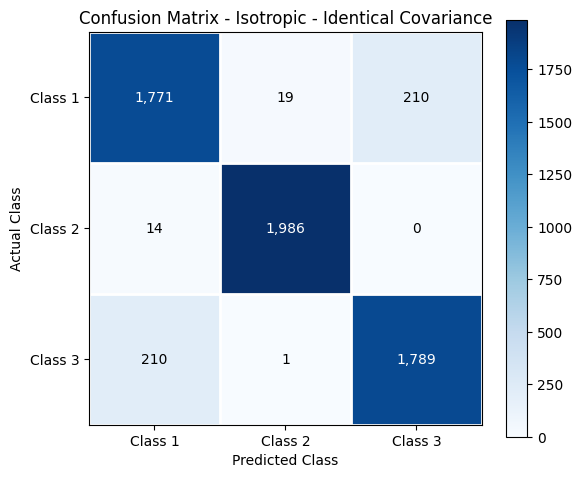

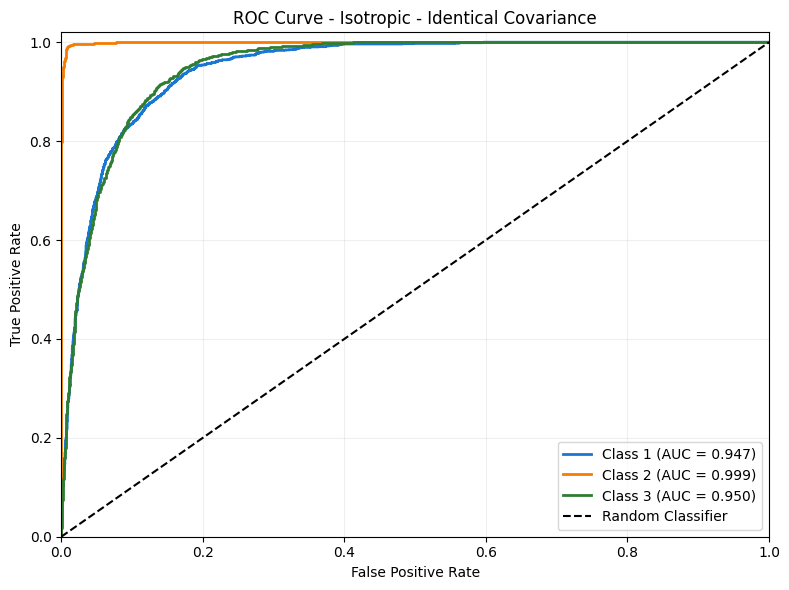


ROC-AUC Values:
Class 1: 0.9473
Class 2: 0.9993
Class 3: 0.9503


In [8]:
result_iso_same = run_experiment(
    "Isotropic - Identical Covariance",
    experiments["Isotropic - Identical"],
    seed=42
)

### Experiment 2: Isotropic – Different Covariance




Isotropic - Different Covariance
Total samples: 30000
Training samples: 24000
Testing samples: 6000

Class 1
Estimated Mean: [ 0.0045 -0.0048]
Estimated Covariance:
[[ 0.9977 -0.0039]
 [-0.0039  0.9794]]

Class 2
Estimated Mean: [5.005 4.992]
Estimated Covariance:
[[2.014  0.0031]
 [0.0031 1.9944]]

Class 3
Estimated Mean: [ 1.9937 -3.0173]
Estimated Covariance:
[[3.0045 0.0144]
 [0.0144 3.0698]]

Test Accuracy: 94.27%


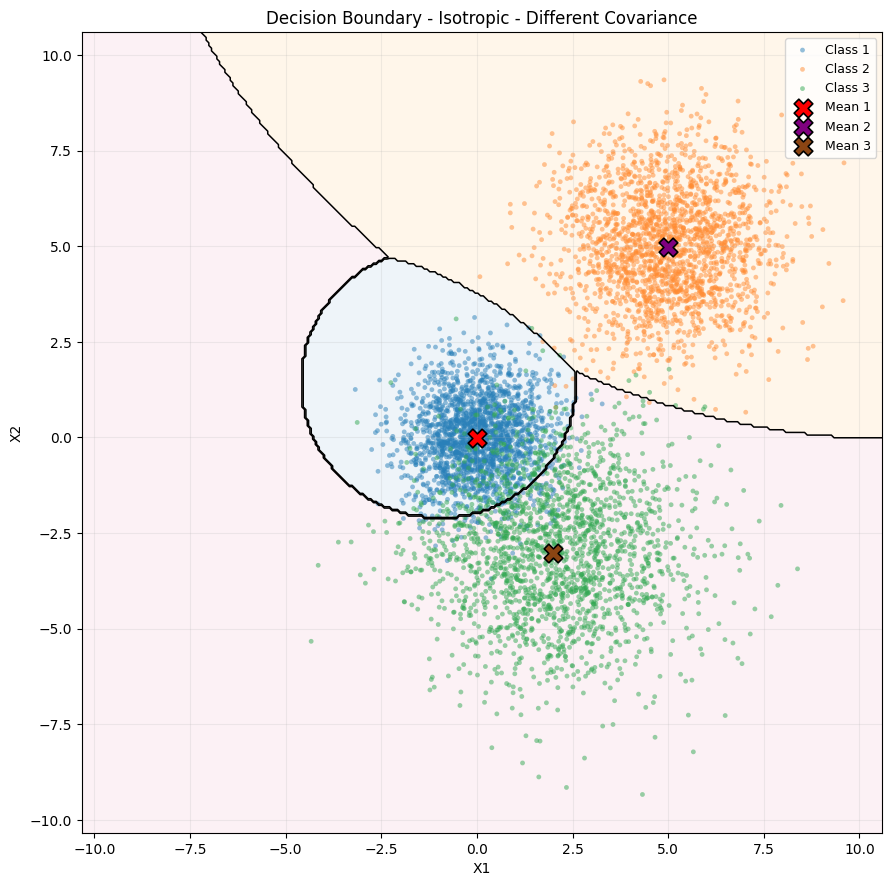


Confusion Matrix:
[[1885    3  112]
 [   5 1993    2]
 [ 213    9 1778]]


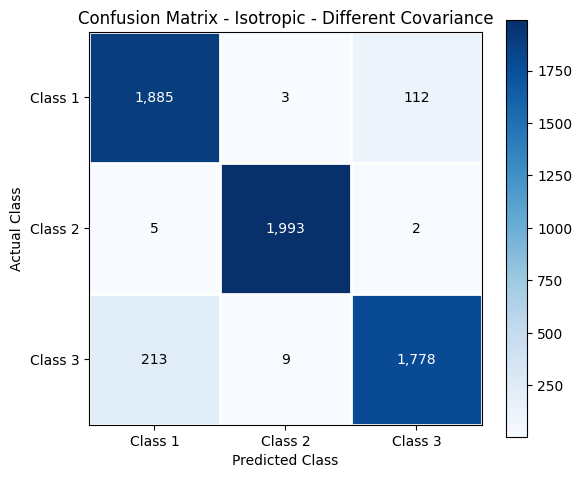

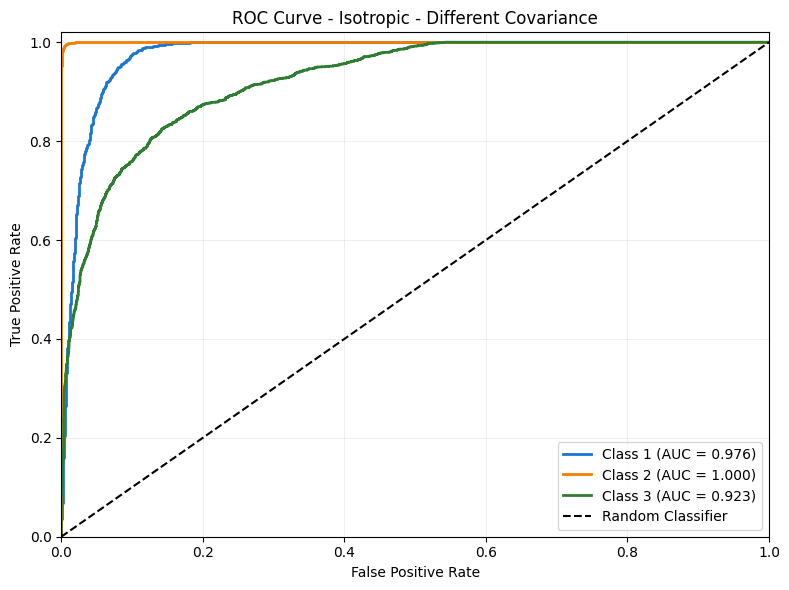


ROC-AUC Values:
Class 1: 0.9764
Class 2: 0.9999
Class 3: 0.9234


In [9]:
result_iso_diff = run_experiment(
    "Isotropic - Different Covariance",
    experiments["Isotropic - Different"],
    seed=43
)

### Experiment 3: Diagonal – Identical Covariance



Diagonal - Identical Covariance
Total samples: 30000
Training samples: 24000
Testing samples: 6000

Class 1
Estimated Mean: [0.0133 0.005 ]
Estimated Covariance:
[[2.0062 0.0075]
 [0.0075 0.9835]]

Class 2
Estimated Mean: [4.9855 4.9998]
Estimated Covariance:
[[1.9891 0.0083]
 [0.0083 1.0047]]

Class 3
Estimated Mean: [ 2.0131 -3.0014]
Estimated Covariance:
[[1.9658 0.004 ]
 [0.004  0.983 ]]

Test Accuracy: 96.20%


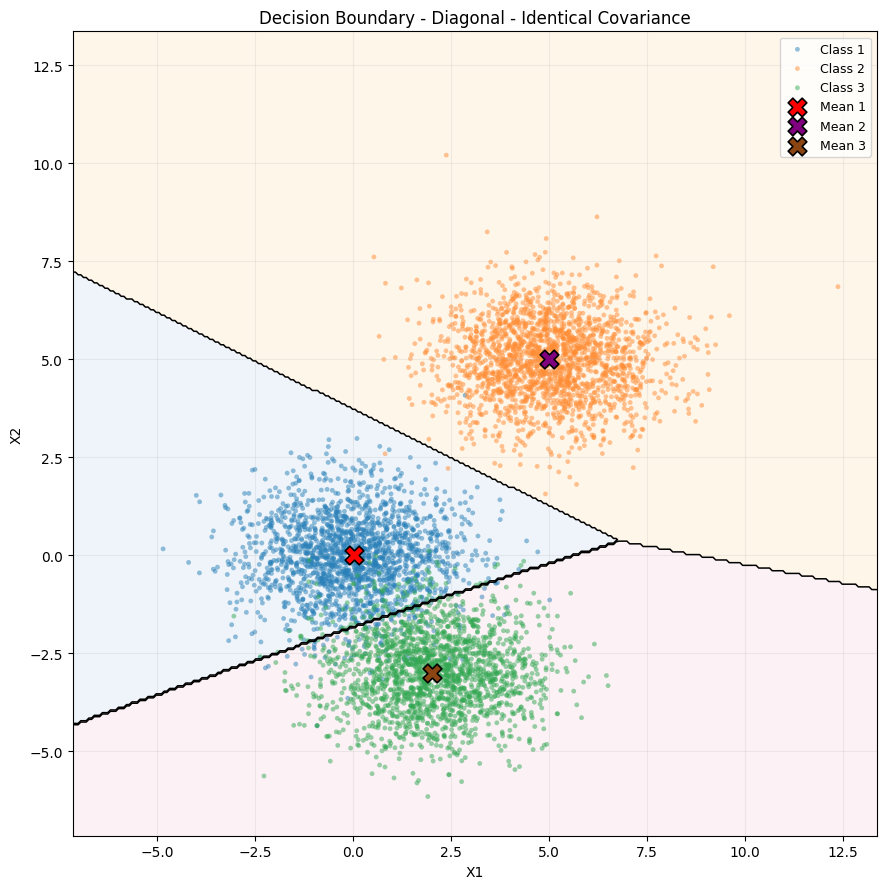


Confusion Matrix:
[[1881    1  118]
 [   2 1998    0]
 [ 107    0 1893]]


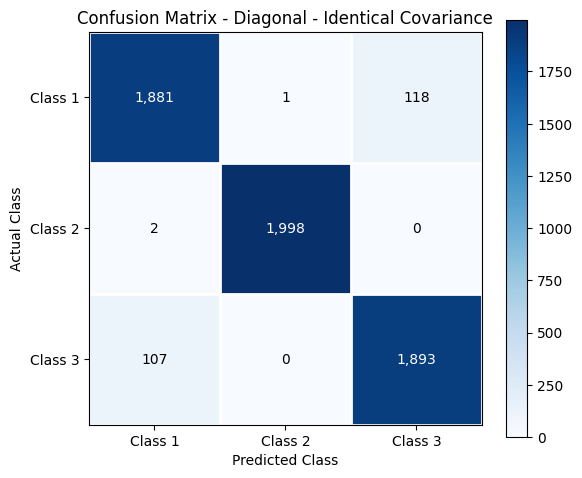

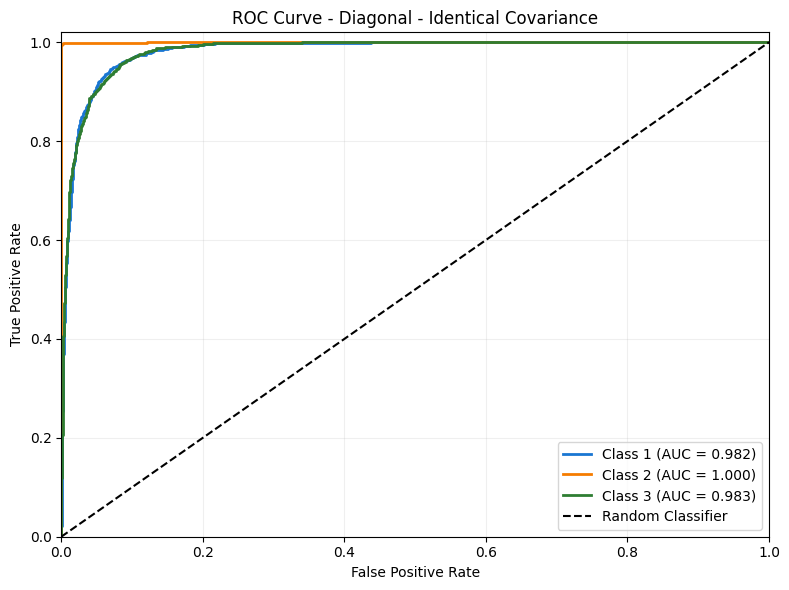


ROC-AUC Values:
Class 1: 0.9825
Class 2: 0.9998
Class 3: 0.9827


In [10]:
result_diag_same = run_experiment(
    "Diagonal - Identical Covariance",
    experiments["Diagonal - Identical"],
    seed=44
)

### Experiment 4: Diagonal – Different Covariance




Diagonal - Different Covariance
Total samples: 30000
Training samples: 24000
Testing samples: 6000

Class 1
Estimated Mean: [0.0129 0.0001]
Estimated Covariance:
[[1.0122 0.0061]
 [0.0061 1.0169]]

Class 2
Estimated Mean: [4.9926 5.008 ]
Estimated Covariance:
[[4.0277 0.0112]
 [0.0112 1.0146]]

Class 3
Estimated Mean: [ 1.9962 -3.0144]
Estimated Covariance:
[[2.0004 0.0129]
 [0.0129 2.9876]]

Test Accuracy: 94.77%


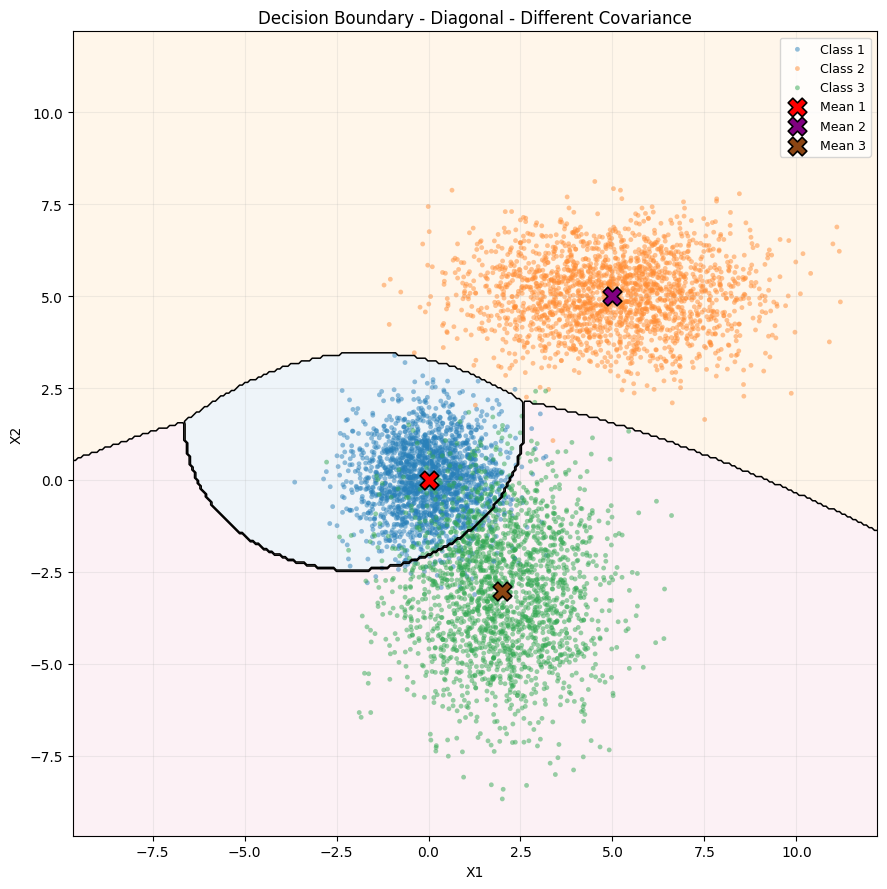


Confusion Matrix:
[[1889    1  110]
 [   1 1998    1]
 [ 198    3 1799]]


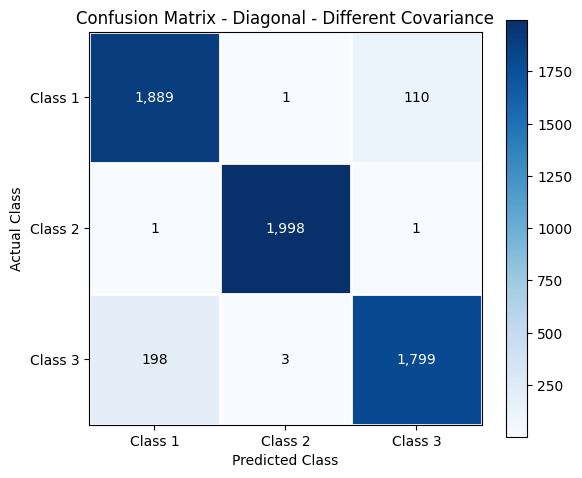

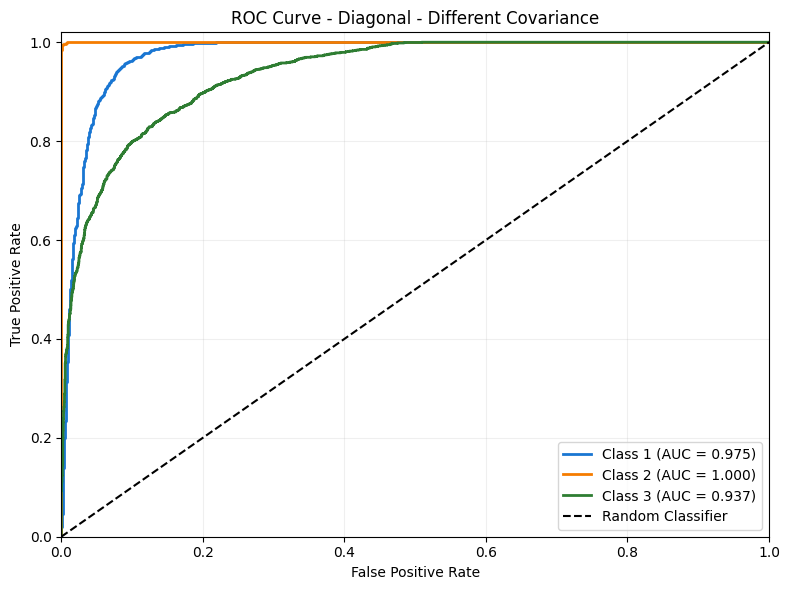


ROC-AUC Values:
Class 1: 0.9754
Class 2: 1.0000
Class 3: 0.9372


In [11]:
result_diag_diff = run_experiment(
    "Diagonal - Different Covariance",
    experiments["Diagonal - Different"],
    seed=45
)

### Experiment 5: Full – Identical Covariance




Full - Identical Covariance
Total samples: 30000
Training samples: 24000
Testing samples: 6000

Class 1
Estimated Mean: [-0.0244 -0.0037]
Estimated Covariance:
[[2.0268 1.0021]
 [1.0021 1.9926]]

Class 2
Estimated Mean: [5.0067 4.9926]
Estimated Covariance:
[[2.0215 1.0111]
 [1.0111 2.0052]]

Class 3
Estimated Mean: [ 2.0455 -2.9796]
Estimated Covariance:
[[2.0091 1.009 ]
 [1.009  2.014 ]]

Test Accuracy: 96.40%


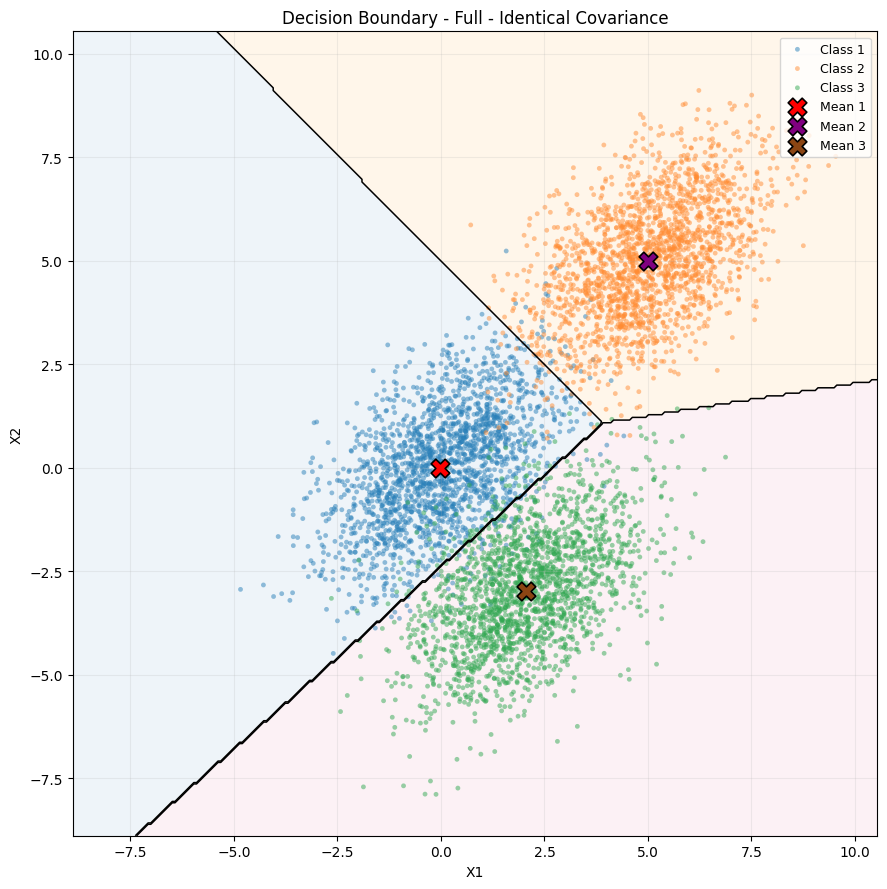


Confusion Matrix:
[[1893   33   74]
 [  29 1969    2]
 [  76    2 1922]]


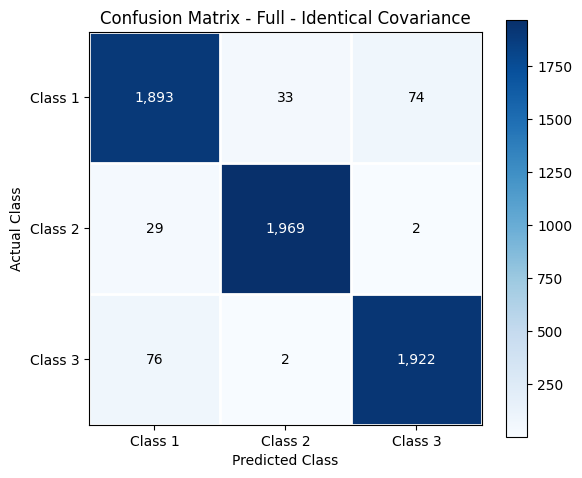

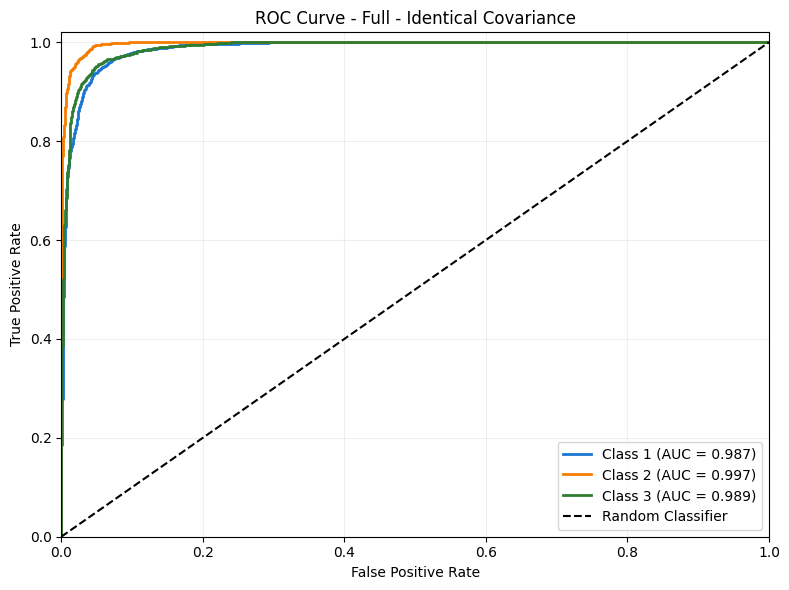


ROC-AUC Values:
Class 1: 0.9870
Class 2: 0.9968
Class 3: 0.9890


In [12]:
result_full_same = run_experiment(
    "Full - Identical Covariance",
    experiments["Full - Identical"],
    seed=46
)

### Experiment 6: Full – Different Covariance




Full - Different Covariance
Total samples: 30000
Training samples: 24000
Testing samples: 6000

Class 1
Estimated Mean: [ 0.0117 -0.0078]
Estimated Covariance:
[[2.03   1.0228]
 [1.0228 2.0243]]

Class 2
Estimated Mean: [4.9961 5.0075]
Estimated Covariance:
[[ 1.9779 -0.9747]
 [-0.9747  1.9407]]

Class 3
Estimated Mean: [ 1.9903 -3.0078]
Estimated Covariance:
[[3.0099 0.7025]
 [0.7025 1.5063]]

Test Accuracy: 96.38%


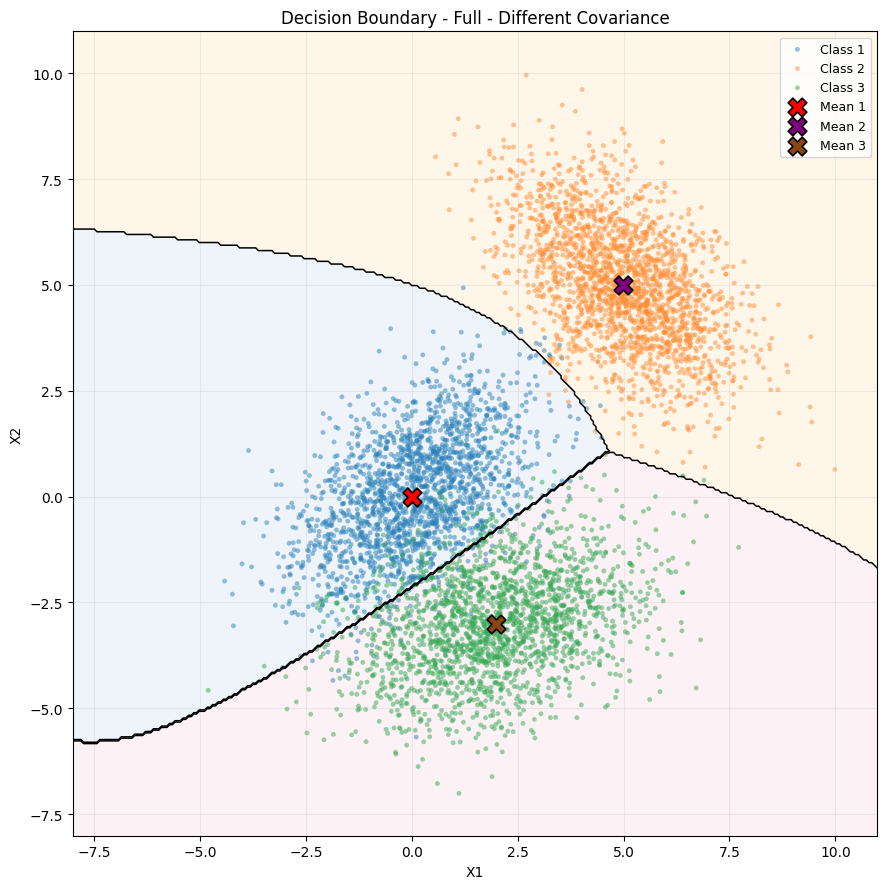


Confusion Matrix:
[[1895   15   90]
 [   5 1995    0]
 [ 105    2 1893]]


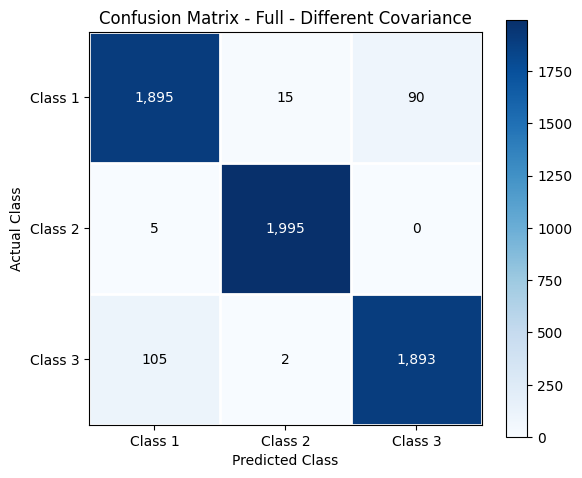

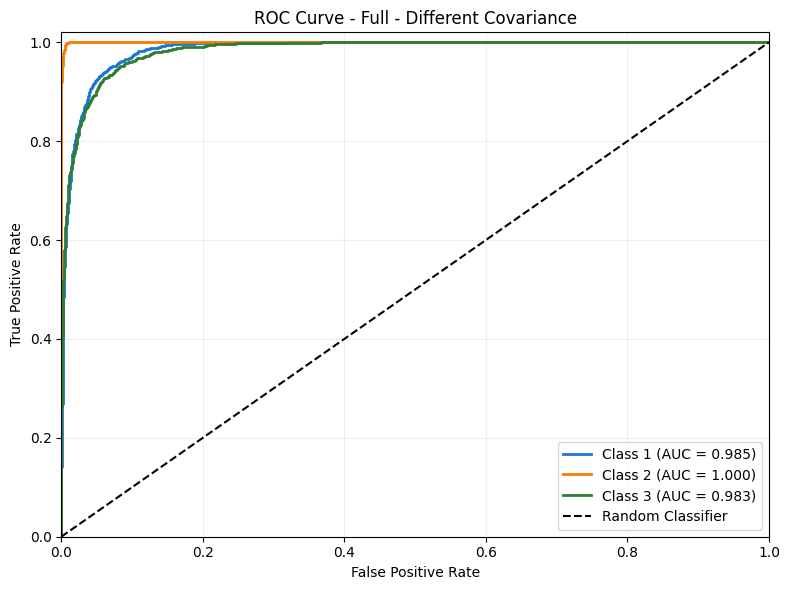


ROC-AUC Values:
Class 1: 0.9849
Class 2: 0.9998
Class 3: 0.9835


In [13]:
result_full_diff = run_experiment(
    "Full - Different Covariance",
    experiments["Full - Different"],
    seed=47
)

### Step 11: Accuracy Comparison


           Experiment  Test Accuracy (%)
Isotropic - Identical              92.43
Isotropic - Different              94.27
 Diagonal - Identical              96.20
 Diagonal - Different              94.77
     Full - Identical              96.40
     Full - Different              96.38


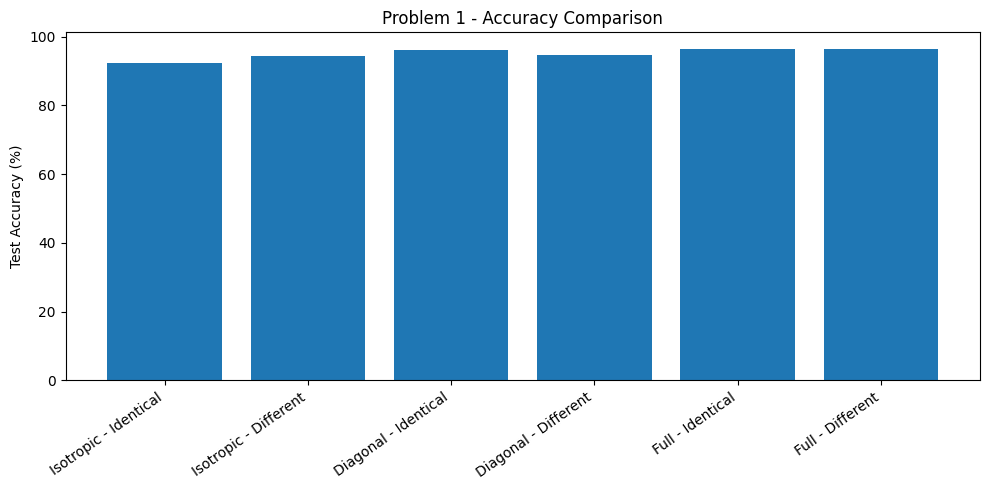

In [14]:
all_results = {
    "Isotropic - Identical": result_iso_same,
    "Isotropic - Different": result_iso_diff,
    "Diagonal - Identical": result_diag_same,
    "Diagonal - Different": result_diag_diff,
    "Full - Identical": result_full_same,
    "Full - Different": result_full_diff
}

comparison = pd.DataFrame([
    {
        "Experiment": name,
        "Test Accuracy (%)": result["accuracy"] * 100
    }
    for name, result in all_results.items()
])

print(comparison.round(2).to_string(index=False))

plt.figure(figsize=(10, 5))
plt.bar(comparison["Experiment"], comparison["Test Accuracy (%)"])
plt.ylabel("Test Accuracy (%)")
plt.title("Problem 1 - Accuracy Comparison")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

### Problem 2: Real Dataset Classification



In [15]:
from google.colab import files
import io

uploaded = files.upload()

filename = next(iter(uploaded))
print("Uploaded file:", filename)

Saving dev.txt to dev.txt
Saving trian.txt to trian.txt
Uploaded file: dev.txt


### Step 13: Read the Dataset


In [16]:
df = pd.read_csv(
    io.BytesIO(uploaded[filename]),
    header=None,
    sep=","
)

df = df.iloc[:, :3].copy()
df.columns = ["x", "y", "class"]

df["x"] = pd.to_numeric(df["x"], errors="coerce")
df["y"] = pd.to_numeric(df["y"], errors="coerce")
df = df.dropna()

print("Total samples:", len(df))
print("\nSamples per class:")
print(df["class"].value_counts())
print("\nFirst five rows:")
print(df.head())

Total samples: 300

Samples per class:
class
1    100
2    100
3    100
Name: count, dtype: int64

First five rows:
        x        y  class
0  389.66  1122.30      1
1  332.48   622.33      1
2  398.64   893.65      1
3  313.47  1345.70      1
4  368.30  1079.40      1


### Step 14: Visualize

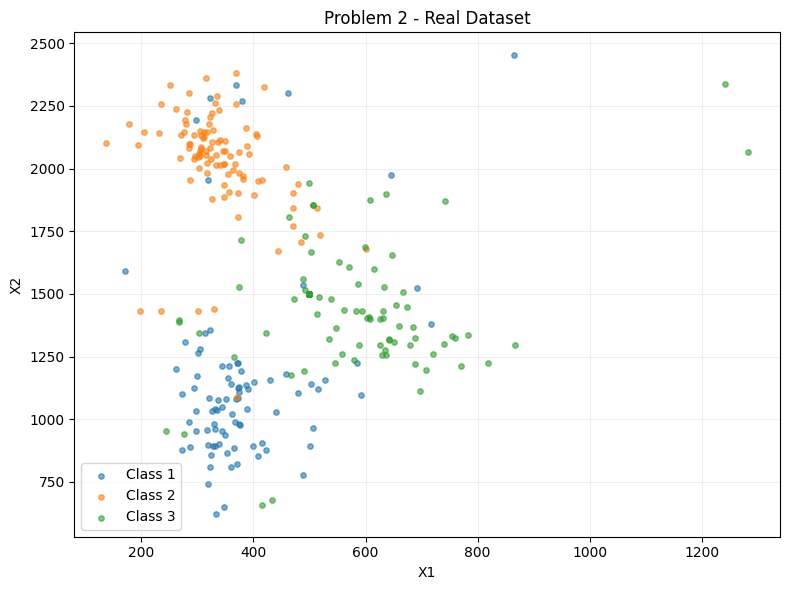

In [17]:
plt.figure(figsize=(8, 6))

for label in sorted(df["class"].unique()):
    subset = df[df["class"] == label]

    plt.scatter(
        subset["x"],
        subset["y"],
        s=15,
        alpha=0.6,
        label=f"Class {label}"
    )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Problem 2 - Real Dataset")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### Step 15: Split into Training and Testing Sets


In [18]:
X_real = df[["x", "y"]].to_numpy(dtype=float)
y_original = df["class"].to_numpy()

X_train_real, X_test_real, y_train_original, y_test_original = (
    train_test_split(
        X_real,
        y_original,
        test_size=0.20,
        random_state=42,
        stratify=y_original
    )
)

classes_original = np.unique(y_train_original)

label_to_number = {
    label: i for i, label in enumerate(classes_original)
}

y_train_real = np.array([
    label_to_number[label] for label in y_train_original
])

y_test_real = np.array([
    label_to_number[label] for label in y_test_original
])

classes_real = list(range(len(classes_original)))

print("Total samples:", len(df))
print("Training samples:", len(X_train_real))
print("Testing samples:", len(X_test_real))
print("Original class labels:", classes_original)

Total samples: 300
Training samples: 240
Testing samples: 60
Original class labels: [1 2 3]


### Step 16: Estimate Parameters Using MLE



In [19]:
estimated_means_real, estimated_covariances_real, priors_real = estimate_mle(
    X_train_real,
    y_train_real,
    classes_real
)

for c in classes_real:
    print(f"\nClass {c + 1} (Original label: {classes_original[c]})")
    print("Estimated Mean:", np.round(estimated_means_real[c], 4))
    print("Estimated Covariance:")
    print(np.round(estimated_covariances_real[c], 4))
    print("Prior Probability:", round(priors_real[c], 4))


Class 1 (Original label: 1)
Estimated Mean: [ 395.3066 1211.0428]
Estimated Covariance:
[[ 11666.25    16763.0831]
 [ 16763.0831 137120.8953]]
Prior Probability: 0.3333

Class 2 (Original label: 2)
Estimated Mean: [ 341.7579 2026.1512]
Estimated Covariance:
[[ 6116.3049 -4458.433 ]
 [-4458.433  40737.9815]]
Prior Probability: 0.3333

Class 3 (Original label: 3)
Estimated Mean: [ 564.3743 1442.1571]
Estimated Covariance:
[[19802.527   3867.6668]
 [ 3867.6668 45076.307 ]]
Prior Probability: 0.3333


### Step 17: Classify the Test Data


In [20]:
scores_real = gaussian_scores(
    X_test_real,
    estimated_means_real,
    estimated_covariances_real,
    priors_real,
    classes_real
)

y_pred_real = np.argmax(scores_real, axis=1)

accuracy_real = accuracy_score(
    y_test_real,
    y_pred_real
)

print(f"Test Accuracy: {accuracy_real * 100:.2f}%")

Test Accuracy: 85.00%


### Step 18: Plot Decision Boundaries


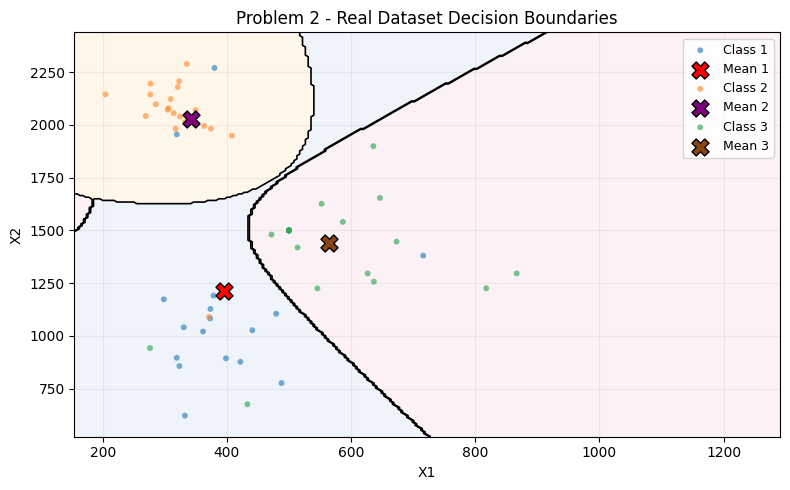

In [31]:
def plot_decision_boundary(
    X_test, y_test, estimated_means,
    estimated_covariances, priors, class_labels, title
):
    x_min = X_test[:, 0].min() - 50
    x_max = X_test[:, 0].max() + 50
    y_min = X_test[:, 1].min() - 100
    y_max = X_test[:, 1].max() + 100

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    grid_scores = gaussian_scores(
        grid, estimated_means, estimated_covariances,
        priors, class_labels
    )

    regions = np.argmax(grid_scores, axis=1).reshape(xx.shape)

    fig, ax = plt.subplots(figsize=(8, 5))

    ax.contourf(
        xx, yy, regions,
        levels=np.arange(len(class_labels) + 1) - 0.5,
        colors=["#EAF2F8", "#FFF4E5", "#FCEEF3"],
        alpha=0.8
    )

    ax.contour(
        xx, yy, regions,
        levels=np.arange(len(class_labels) - 1) + 0.5,
        colors="black",
        linewidths=1.2
    )

    point_colors = ["#2980B9", "#FF8C33", "#32A852"]
    mean_colors = ["red", "purple", "saddlebrown"]

    for i, c in enumerate(class_labels):
        mask = y_test == c

        ax.scatter(
            X_test[mask, 0], X_test[mask, 1],
            s=18,
            color=point_colors[i % 3],
            alpha=0.65,
            edgecolors="none",
            label=f"Class {i + 1}"
        )

        mean = estimated_means[c]
        ax.scatter(
            mean[0], mean[1],
            marker="X",
            s=150,
            color=mean_colors[i % 3],
            edgecolors="black",
            label=f"Mean {i + 1}",
            zorder=5
        )

    ax.set_xlim(x_min, x_max)
    ax.set_ylim(y_min, y_max)
    ax.set_aspect("auto")
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_title(title)
    ax.legend(loc="upper right", fontsize=9)
    ax.grid(alpha=0.2)

    fig.tight_layout()
    plt.show()

plot_decision_boundary(
    X_test_real,
    y_test_real,
    estimated_means_real,
    estimated_covariances_real,
    priors_real,
    classes_real,
    "Problem 2 - Real Dataset Decision Boundaries"
)

### Step 19: Generate the Confusion Matrix




Confusion Matrix:
[[14  2  4]
 [ 1 19  0]
 [ 2  0 18]]


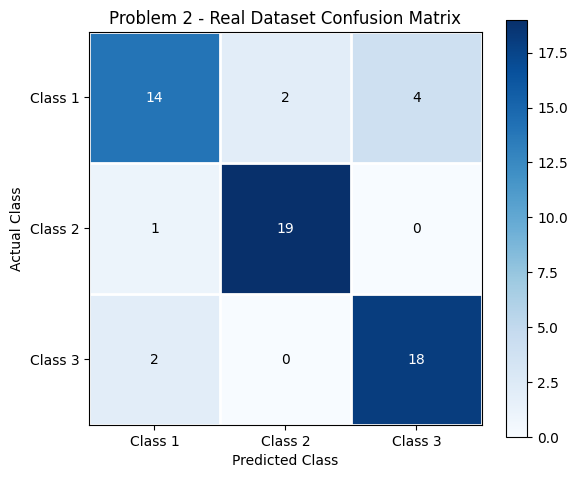


Confusion Matrix Table:
                Predicted Class 1  Predicted Class 2  Predicted Class 3
Actual Class 1                 14                  2                  4
Actual Class 2                  1                 19                  0
Actual Class 3                  2                  0                 18


In [32]:
cm_real = plot_confusion_matrix(
    y_test_real,
    y_pred_real,
    classes_real,
    "Problem 2 - Real Dataset Confusion Matrix"
)

print("\nConfusion Matrix Table:")

cm_table_real = pd.DataFrame(
    cm_real,
    index=[f"Actual Class {i + 1}" for i in range(len(classes_real))],
    columns=[f"Predicted Class {i + 1}" for i in range(len(classes_real))]
)

print(cm_table_real)

### Step 20: Plot the ROC Curve



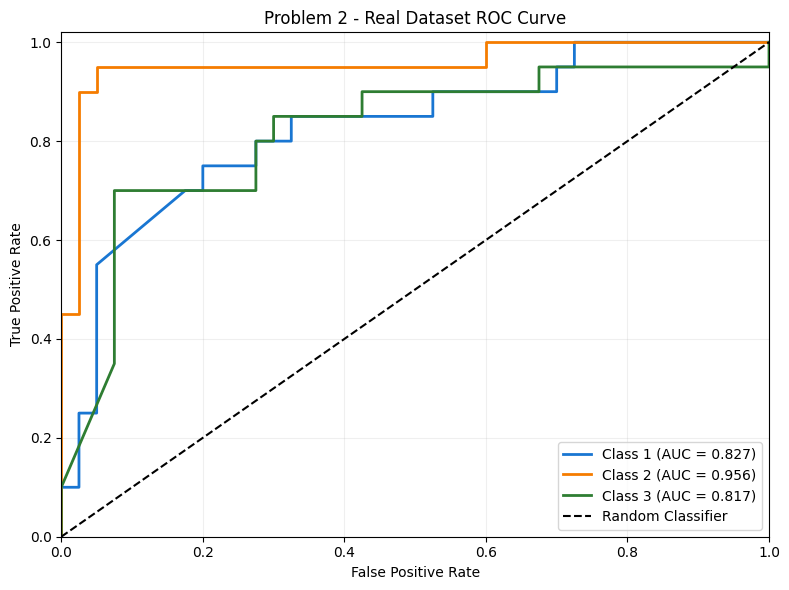


ROC-AUC Values:
Class 1: 0.8269
Class 2: 0.9562
Class 3: 0.8169


In [33]:
auc_real = plot_roc(
    y_test_real,
    scores_real,
    classes_real,
    "Problem 2 - Real Dataset ROC Curve"
)

### Step 21: Final Results


In [34]:
print("PROBLEM 2 - FINAL RESULTS")

print("Total samples:", len(df))
print("Training samples:", len(X_train_real))
print("Testing samples:", len(X_test_real))
print(f"Test Accuracy: {accuracy_real * 100:.2f}%")

print("\nConfusion Matrix:")
print(cm_table_real)

print("\nROC-AUC Values:")
for i, c in enumerate(classes_real):
    print(f"Class {i + 1} (label {classes_original[c]}): {auc_real[c]:.4f}")

PROBLEM 2 - FINAL RESULTS
Total samples: 300
Training samples: 240
Testing samples: 60
Test Accuracy: 85.00%

Confusion Matrix:
                Predicted Class 1  Predicted Class 2  Predicted Class 3
Actual Class 1                 14                  2                  4
Actual Class 2                  1                 19                  0
Actual Class 3                  2                  0                 18

ROC-AUC Values:
Class 1 (label 1): 0.8269
Class 2 (label 2): 0.9562
Class 3 (label 3): 0.8169
